# Relative strength rotation — rebalance frequency experiment

The live intraday script (`relative_strength_rotation/live/relative_strength_rotation_webull_intraday.py`) rebalances
every 2 hours (8:30/10:30/12:30/2:30 CT) on a 6-hourly-bar lookback, a cadence that was chosen
by analogy to the monthly strategy's 3:1 lookback:rebalance ratio, **not validated against
data**. This notebook is that validation: it treats the rebalance interval itself as a
parameter to test, instead of reasoning it out in advance, and asks three separate questions:

1. **Experiment 1 — interval sweep.** Holding the live script's signal fixed (trailing return
   over `LOOKBACK_BARS=6` hourly bars), how does performance change as the rebalance cadence
   varies from every bar to every 6 bars (~1 trading day)? Reported gross (no costs) and across
   a grid of assumed per-trade cost levels, since turnover differs enormously by cadence.
2. **Experiment 2 — signal decay.** Rather than assume a rebalance interval and check if it
   works, directly measure how long the trailing-return score stays predictive via the
   cross-sectional information coefficient (IC) at increasing forward horizons. This answers
   "how often does the ranking actually contain new information" independent of any clock.
3. **Experiment 3 — hysteresis band.** Re-rank every hour, but only replace a held name once it
   falls far enough out of the top 10 (a rank buffer), instead of fully rebalancing to a fresh
   top 10 every cycle. This tests whether "measure often, trade selectively" reduces turnover
   without giving up the gross return the frequent re-ranking would otherwise capture.

**Scope limit, stated up front:** the cached data (`data/hourly/{TICKER}.csv`, from IBKR) is
hourly-bar granularity — 09:30's half-hour bar plus six 1-hour bars, 7 bars/session. That means
every interval tested here is a whole multiple of 1 hour. True 15/30-minute rebalancing, and a
genuine time-of-day-adaptive schedule (faster near the open/close, slower midday), would need
finer bars fetched from IBKR first — not done here. If the hourly-level results below look
promising enough to justify it, fetching 15-minute bars for a follow-up notebook is the natural
next step, not a starting assumption.

Universe, scoring, and fallback behavior (hold the previous basket if fewer than
`MIN_UNIVERSE` names are scoreable) are identical to the existing single-cadence notebook
(`relative_strength_rotation_intraday_backtest.ipynb`) and to the live script itself.

In [1]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

EQUITIES_LIST_PATH = Path('..') / 'equities-list.csv'
DATA_DIR = Path('..') / 'data' / 'hourly'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

START_DATE = pd.Timestamp('2009-01-01', tz='UTC')

# Signal is held fixed at the live script's current setting throughout Experiments 1 and 3 —
# the question this notebook asks is "how often to re-rank/trade", not "how long a lookback",
# which is a separate parameter this notebook deliberately does not re-tune.
LOOKBACK_BARS = 6        # trailing-return lookback, hourly bars (~1 trading day) — matches the live script
TOP_N = 10               # concentrated top-10 roster, same as every other notebook in this project
MIN_UNIVERSE = 15        # minimum scoreable names required before trading a given cycle

BARS_PER_SESSION = 7     # 09:30 half-hour bar + six 1-hour bars
TRADING_DAYS_PER_YEAR = 252

REBALANCE_CANDIDATES = [1, 2, 3, 4, 6]       # hourly-bar cadences tested in Experiment 1 (2 = the live script's current setting)
COST_BPS_GRID = [0, 1, 2, 5, 10, 20]         # assumed ROUND-TRIP cost per unit of turnover, in bps — not fitted to real spreads, see caveats
HORIZONS_BARS = [1, 2, 3, 4, 6, 12, 24]      # forward horizons (hourly bars) tested in the IC decay analysis
HYSTERESIS_BUFFERS = [0, 3, 5, 10, 20]       # rank slack before a held name is forced out, tested in Experiment 3
REFERENCE_COST_BPS = 5                       # cost level used to rank variants in the combined comparison at the end

132 candidate halal stocks in the universe


## Load the cached hourly bars

Reuses the same `data/hourly/{TICKER}.csv` cache the live script and the single-cadence
notebook share — built once from IBKR, read-only here.

In [2]:
def load_cached_hourly(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

hourly_closes = {}
missing = []
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        missing.append(ticker)
        continue
    bars = load_cached_hourly(ticker)
    if bars.empty:
        missing.append(ticker)
        continue
    hourly_closes[ticker] = bars['close']

if missing:
    print(f'{len(missing)} tickers missing from the hourly cache, excluded: {missing}')

price_panel = pd.DataFrame(hourly_closes).sort_index()
price_panel = price_panel.loc[price_panel.index >= START_DATE]
# Fill isolated missing bars (at most one session) so bar-count rolling windows stay contiguous,
# same convention as the single-cadence notebook.
price_panel = price_panel.ffill(limit=BARS_PER_SESSION)

print(f'{price_panel.shape[1]} tickers, {price_panel.shape[0]:,} hourly bars '
      f'from {price_panel.index.min()} to {price_panel.index.max()}')

132 tickers, 32,366 hourly bars from 2009-01-02 14:30:00+00:00 to 2026-09-30 16:00:00+00:00


## Experiment 1 — rebalance cadence sweep

Same decision loop as the single-cadence notebook, generalized to take `rebalance_bars` as a
parameter: every `rebalance_bars` bars, score the universe by trailing `LOOKBACK_BARS`-bar
return, pick the top 10, and record the equal-weighted average return of that basket over the
next `rebalance_bars` bars. `rebalance_bars=2` reproduces the live script's current setting
exactly; the other candidates show what else was available.

In [3]:
def run_strategy(price_panel, lookback_bars, rebalance_bars, top_n=TOP_N, min_universe=MIN_UNIVERSE):
    dates = price_panel.index
    n = len(dates)
    min_i = lookback_bars + rebalance_bars
    portfolio_returns = pd.Series(index=dates, dtype=float)
    turnover_log = {}
    holdings_log = {}
    previous_holdings = set()

    for j in range(min_i, n - rebalance_bars, rebalance_bars):
        score = (price_panel.iloc[j] / price_panel.iloc[j - lookback_bars] - 1).dropna()
        hold_start_date, hold_end_date = dates[j], dates[j + rebalance_bars]

        if len(score) < min_universe:
            selected = sorted(previous_holdings)
        else:
            selected = score.sort_values(ascending=False).head(top_n).index.tolist()

        holdings_log[hold_end_date] = selected
        if selected:
            realized = (price_panel.loc[hold_end_date, selected] / price_panel.loc[hold_start_date, selected] - 1).dropna()
            portfolio_returns.loc[hold_end_date] = realized.mean() if len(realized) else np.nan
            turnover_log[hold_end_date] = len(set(selected) - previous_holdings) / top_n
        else:
            portfolio_returns.loc[hold_end_date] = np.nan
            turnover_log[hold_end_date] = 0.0
        previous_holdings = set(selected)

    portfolio_returns = portfolio_returns.dropna()
    turnover = pd.Series(turnover_log).reindex(portfolio_returns.index)
    return portfolio_returns, turnover, holdings_log


t0 = time.time()
experiment1_results = {}
for rb in REBALANCE_CANDIDATES:
    pr, to, hl = run_strategy(price_panel, LOOKBACK_BARS, rb)
    experiment1_results[rb] = (pr, to)
    print(f'rebalance_bars={rb} (~{rb}h cadence): {len(pr):,} cycles, avg turnover {to.mean():.1%} of the roster/cycle')
print(f'done in {time.time() - t0:.0f}s')

rebalance_bars=1 (~1h cadence): 32,358 cycles, avg turnover 36.6% of the roster/cycle


rebalance_bars=2 (~2h cadence): 16,178 cycles, avg turnover 50.6% of the roster/cycle


rebalance_bars=3 (~3h cadence): 10,785 cycles, avg turnover 61.6% of the roster/cycle


rebalance_bars=4 (~4h cadence): 8,088 cycles, avg turnover 71.0% of the roster/cycle


rebalance_bars=6 (~6h cadence): 5,392 cycles, avg turnover 86.5% of the roster/cycle
done in 47s


### Cost-sensitivity stats

No notebook in this project has modeled transaction costs numerically before — they're all
flagged as a caveat and skipped. That's reasonable for the monthly strategies (~12
cycles/year), but this strategy rebalances up to ~1,750 times a year at `rebalance_bars=1`, so
a cost that's a rounding error monthly can dominate here. Rather than pick one "true" cost
number (commissions are $0 on Webull, but bid/ask spread and slippage aren't), this applies a
**round-trip bps cost proportional to each cycle's turnover** across `COST_BPS_GRID`, so the
sensitivity itself is visible rather than hidden behind a single assumption.

`net_pnl_per_turnover` is the total-return-to-total-turnover ratio the earlier analysis
flagged as the more informative comparison than raw gross return — a cadence with a lower
gross CAGR but far less turnover can still be the better real-world choice.

In [4]:
def compute_stats(portfolio_returns, turnover, periods_per_year, cost_bps=0.0):
    net_returns = portfolio_returns - (cost_bps / 10_000.0) * turnover
    wealth = (1 + net_returns).cumprod()
    start_date, end_date = portfolio_returns.index[0], portfolio_returns.index[-1]
    years = (end_date - start_date).days / 365.2425
    total_return = float(wealth.iloc[-1] - 1.0)
    cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0) if years > 0 else float('nan')
    annualized_volatility = float(net_returns.std() * np.sqrt(periods_per_year))
    sharpe = float((net_returns.mean() * periods_per_year) / annualized_volatility) if annualized_volatility else float('nan')
    max_dd = float((wealth / wealth.cummax() - 1.0).min())
    total_turnover = float(turnover.sum())
    net_pnl_per_turnover = float(total_return / total_turnover) if total_turnover else float('nan')
    return {
        'cycles': len(portfolio_returns), 'avg_turnover': float(turnover.mean()),
        'CAGR': cagr, 'ann_vol': annualized_volatility, 'sharpe': sharpe, 'max_dd': max_dd,
        'total_return': total_return, 'net_pnl_per_turnover': net_pnl_per_turnover,
    }

rows = []
for rb, (pr, to) in experiment1_results.items():
    periods_per_year = (BARS_PER_SESSION * TRADING_DAYS_PER_YEAR) / rb
    for cost in COST_BPS_GRID:
        stats = compute_stats(pr, to, periods_per_year, cost_bps=cost)
        rows.append({'rebalance_bars': rb, 'cost_bps': cost, **stats})
experiment1_summary = pd.DataFrame(rows)

gross = experiment1_summary[experiment1_summary['cost_bps'] == 0].set_index('rebalance_bars')
print('Gross (no-cost) comparison — pure signal quality by cadence:')
display(gross[['cycles', 'avg_turnover', 'CAGR', 'sharpe', 'max_dd']].round(4))

print('\nCAGR by cadence x assumed cost (bps):')
display((experiment1_summary.pivot(index='rebalance_bars', columns='cost_bps', values='CAGR') * 100).round(1))

print('\nnet_pnl_per_turnover by cadence x assumed cost (bps):')
display(experiment1_summary.pivot(index='rebalance_bars', columns='cost_bps', values='net_pnl_per_turnover').round(5))

Gross (no-cost) comparison — pure signal quality by cadence:


,cycles,avg_turnover,CAGR,sharpe,max_dd
rebalance_bars,,,,,
1,32358,0.3656,0.0191,0.2006,-0.6903
2,16178,0.5058,0.1804,0.7535,-0.4530
3,10785,0.6162,0.1648,0.7080,-0.4383
4,8088,0.7098,0.1443,0.6427,-0.4253
6,5392,0.8645,0.1828,0.7704,-0.3764



CAGR by cadence x assumed cost (bps):


cost_bps,0,1,2,5,10,20
rebalance_bars,,,,,,
1,1.9,-4.7,-10.8,-27.0,-47.7,-73.2
2,18.0,12.7,7.6,-6.3,-25.6,-53.1
3,16.5,12.2,8.1,-3.4,-19.9,-45.0
4,14.4,10.8,7.3,-2.7,-17.2,-40.1
6,18.3,15.2,12.2,3.7,-9.1,-30.1



net_pnl_per_turnover by cadence x assumed cost (bps):


cost_bps,0,1,2,5,10,20
rebalance_bars,,,,,,
1,0.00003,-0.00005,-0.00007,-0.00008,-0.00008,-0.00008
2,0.00219,0.00090,0.00033,-0.00008,-0.00012,-0.00012
3,0.00210,0.00101,0.00044,-0.00007,-0.00015,-0.00015
4,0.00173,0.00090,0.00043,-0.00007,-0.00017,-0.00017
6,0.00399,0.00243,0.00144,0.00019,-0.00017,-0.00021


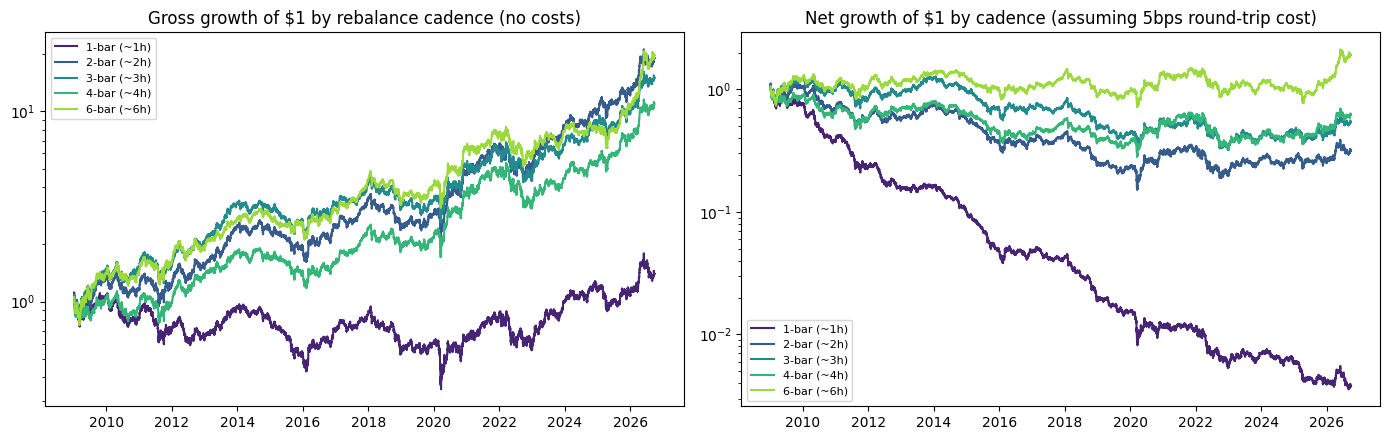

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(REBALANCE_CANDIDATES)))

for rb, c in zip(REBALANCE_CANDIDATES, colors):
    pr, to = experiment1_results[rb]
    wealth = (1 + pr).cumprod()
    axes[0].plot(wealth.index, wealth.values, color=c, label=f'{rb}-bar (~{rb}h)')
axes[0].set_yscale('log')
axes[0].set_title('Gross growth of $1 by rebalance cadence (no costs)')
axes[0].legend(fontsize=8)

for rb, c in zip(REBALANCE_CANDIDATES, colors):
    pr, to = experiment1_results[rb]
    net = pr - (REFERENCE_COST_BPS / 10_000.0) * to
    wealth_net = (1 + net).cumprod()
    axes[1].plot(wealth_net.index, wealth_net.values, color=c, label=f'{rb}-bar (~{rb}h)')
axes[1].set_yscale('log')
axes[1].set_title(f'Net growth of $1 by cadence (assuming {REFERENCE_COST_BPS}bps round-trip cost)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Experiment 2 — signal decay (information coefficient by horizon)

Instead of assuming a holding period and checking if it works, this measures directly: at
every hourly bar, compute the trailing `LOOKBACK_BARS`-bar score for the whole universe, and
the Spearman rank correlation (IC) between that score and each stock's **forward** return over
`h` bars, for `h` in `HORIZONS_BARS`. Averaging IC across all bars in the history gives the
"natural" horizon over which the ranking actually contains information — independent of
whatever cadence Experiment 1 happens to test.

Note this is a genuinely different lens from Experiment 1: IC measures the average rank
correlation across the **whole** cross-section, while Experiment 1's backtest only measures
the realized return of the **top-10 tail** of that same ranking. A weak or even negative
average IC does not automatically mean the top-decile backtest is wrong — tail behavior can
diverge from the whole-population correlation — but a consistently weak IC across every
horizon is still a real warning sign about how much of Experiment 1's apparent edge to trust.
This takes a couple of minutes to run (one Spearman correlation per bar per horizon, ~32k bars).

In [6]:
t0 = time.time()
score_matrix = price_panel / price_panel.shift(LOOKBACK_BARS) - 1.0  # trailing LOOKBACK_BARS-bar return, every bar

ic_rows = []
for h in HORIZONS_BARS:
    fwd_return = price_panel.shift(-h) / price_panel - 1.0
    ics = []
    for j in range(LOOKBACK_BARS, len(price_panel) - h):
        s = score_matrix.iloc[j].dropna()
        f = fwd_return.iloc[j].reindex(s.index).dropna()
        common = s.index.intersection(f.index)
        if len(common) < MIN_UNIVERSE:
            continue
        rho, _ = spearmanr(s.loc[common], f.loc[common])
        if not np.isnan(rho):
            ics.append(rho)
    ics = np.array(ics)
    ic_rows.append({
        'horizon_bars': h, 'n_bars': len(ics), 'mean_ic': ics.mean(), 'std_ic': ics.std(),
        'ic_ir': ics.mean() / ics.std() if ics.std() else np.nan,
    })
    print(f'horizon={h} bars: mean IC={ics.mean():+.4f}, IR={ic_rows[-1]["ic_ir"]:+.3f} ({time.time() - t0:.0f}s elapsed)')

ic_table = pd.DataFrame(ic_rows).set_index('horizon_bars')
display(ic_table.round(4))

/tmp/ipykernel_25993/586264818.py:14: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(s.loc[common], f.loc[common])


horizon=1 bars: mean IC=-0.0198, IR=-0.109 (20s elapsed)


horizon=2 bars: mean IC=-0.0204, IR=-0.109 (39s elapsed)


horizon=3 bars: mean IC=-0.0211, IR=-0.112 (59s elapsed)


horizon=4 bars: mean IC=-0.0214, IR=-0.113 (77s elapsed)


horizon=6 bars: mean IC=-0.0213, IR=-0.111 (98s elapsed)


horizon=12 bars: mean IC=-0.0170, IR=-0.088 (118s elapsed)


horizon=24 bars: mean IC=-0.0167, IR=-0.088 (137s elapsed)


,n_bars,mean_ic,std_ic,ic_ir
horizon_bars,,,,
1,31918,-0.0198,0.1823,-0.1088
2,32066,-0.0204,0.1866,-0.1095
3,32192,-0.0211,0.1886,-0.1119
4,32307,-0.0214,0.1901,-0.1128
6,32352,-0.0213,0.1931,-0.1105
12,32348,-0.0170,0.1938,-0.0877
24,32336,-0.0167,0.1888,-0.0884


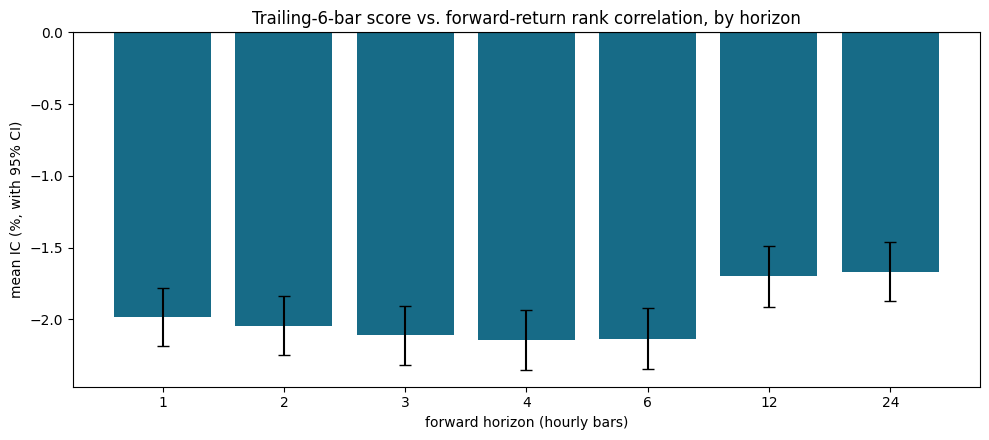

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(ic_table.index.astype(str), ic_table['mean_ic'] * 100,
       yerr=(ic_table['std_ic'] / np.sqrt(ic_table['n_bars'])) * 100 * 1.96, capsize=4, color='#176b87')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('forward horizon (hourly bars)')
ax.set_ylabel('mean IC (%, with 95% CI)')
ax.set_title('Trailing-6-bar score vs. forward-return rank correlation, by horizon')
plt.tight_layout()
plt.show()

## Experiment 3 — hysteresis band ("measure often, trade selectively")

Re-ranks the universe every single hourly bar (the finest granularity this data supports), but
a held name is only forced out once its rank falls below `TOP_N + exit_buffer`, rather than
fully rebalancing to a fresh top 10 every cycle. A vacancy (from an exit, or at startup) is
filled by the best-ranked name not already held. `exit_buffer=0` is a pure sanity check: it
should (and does, up to a single startup-bar difference) reproduce Experiment 1's
`rebalance_bars=1` result exactly, since both are just "hold the strict top 10, re-evaluated
every bar" computed two different ways.

In [8]:
def run_strategy_hysteresis(price_panel, lookback_bars, top_n, exit_buffer, min_universe=MIN_UNIVERSE):
    dates = price_panel.index
    n = len(dates)
    score_matrix = price_panel / price_panel.shift(lookback_bars) - 1.0
    fwd_ret_1bar = price_panel.shift(-1) / price_panel - 1.0

    portfolio_returns = pd.Series(index=dates, dtype=float)
    turnover_log = pd.Series(index=dates, dtype=float)
    holdings = set()
    for j in range(lookback_bars, n - 1):
        score_j = score_matrix.iloc[j].dropna()
        if len(score_j) >= min_universe:
            ranks = score_j.rank(ascending=False, method='first')
            exits = {t for t in holdings if (t not in ranks.index) or (ranks[t] > top_n + exit_buffer)}
            holdings -= exits
            vacancies = top_n - len(holdings)
            if vacancies > 0:
                # NOTE: pd.Index.difference() silently sorts its result alphabetically, which
                # would scramble the rank ordering here — iterate ranks.sort_values().index
                # directly and filter instead of using .difference().
                candidates = [t for t in ranks.sort_values().index if t not in holdings]
                adds = candidates[:vacancies]
                holdings |= set(adds)
            else:
                adds = []
            turnover_log.iloc[j] = len(adds) / top_n
        else:
            turnover_log.iloc[j] = 0.0
        if holdings:
            r = fwd_ret_1bar.loc[dates[j], list(holdings)].dropna()
            portfolio_returns.iloc[j] = r.mean() if len(r) else np.nan
        else:
            portfolio_returns.iloc[j] = np.nan
    portfolio_returns = portfolio_returns.dropna()
    turnover_log = turnover_log.reindex(portfolio_returns.index)
    return portfolio_returns, turnover_log


t0 = time.time()
experiment3_results = {}
for buf in HYSTERESIS_BUFFERS:
    pr, to = run_strategy_hysteresis(price_panel, LOOKBACK_BARS, TOP_N, buf)
    experiment3_results[buf] = (pr, to)
    print(f'exit_buffer={buf:3d}: {len(pr):,} bars, avg turnover {to.mean():.1%} ({time.time() - t0:.0f}s elapsed)')

sanity_pr, sanity_to = experiment3_results[0]
baseline_pr, baseline_to = experiment1_results[1]
print(f'\nsanity check — exit_buffer=0 vs. Experiment 1 rebalance_bars=1: '
      f'avg turnover {sanity_to.mean():.4f} vs {baseline_to.mean():.4f}, '
      f'mean per-cycle return {sanity_pr.mean():.6f} vs {baseline_pr.mean():.6f}')

exit_buffer=  0: 32,359 bars, avg turnover 36.6% (15s elapsed)


exit_buffer=  3: 32,359 bars, avg turnover 29.9% (29s elapsed)


exit_buffer=  5: 32,359 bars, avg turnover 27.3% (43s elapsed)


exit_buffer= 10: 32,359 bars, avg turnover 23.4% (178s elapsed)


exit_buffer= 20: 32,359 bars, avg turnover 19.6% (190s elapsed)

sanity check — exit_buffer=0 vs. Experiment 1 rebalance_bars=1: avg turnover 0.3656 vs 0.3656, mean per-cycle return 0.000029 vs 0.000030


In [9]:
rows = []
periods_per_year_hourly = BARS_PER_SESSION * TRADING_DAYS_PER_YEAR
for buf, (pr, to) in experiment3_results.items():
    for cost in COST_BPS_GRID:
        stats = compute_stats(pr, to, periods_per_year_hourly, cost_bps=cost)
        rows.append({'exit_buffer': buf, 'cost_bps': cost, **stats})
experiment3_summary = pd.DataFrame(rows)

gross3 = experiment3_summary[experiment3_summary['cost_bps'] == 0].set_index('exit_buffer')
print('Gross (no-cost) comparison — pure signal quality by hysteresis buffer:')
display(gross3[['avg_turnover', 'CAGR', 'sharpe', 'max_dd']].round(4))

print('\nCAGR by buffer x assumed cost (bps):')
display((experiment3_summary.pivot(index='exit_buffer', columns='cost_bps', values='CAGR') * 100).round(1))

Gross (no-cost) comparison — pure signal quality by hysteresis buffer:


,avg_turnover,CAGR,sharpe,max_dd
exit_buffer,,,,
0,0.3656,0.0181,0.1967,-0.6885
3,0.2988,0.0317,0.2463,-0.6259
5,0.2728,0.0397,0.2750,-0.6042
10,0.2344,0.0618,0.3533,-0.6140
20,0.1962,0.0737,0.3965,-0.5429



CAGR by buffer x assumed cost (bps):


cost_bps,0,1,2,5,10,20
exit_buffer,,,,,,
0,1.8,-4.8,-10.9,-27.1,-47.7,-73.2
3,3.2,-2.3,-7.5,-21.4,-40.2,-65.3
5,4.0,-1.1,-5.9,-18.9,-36.8,-61.6
10,6.2,1.7,-2.5,-14.3,-30.8,-54.9
20,7.4,3.6,-0.1,-10.2,-24.9,-47.5


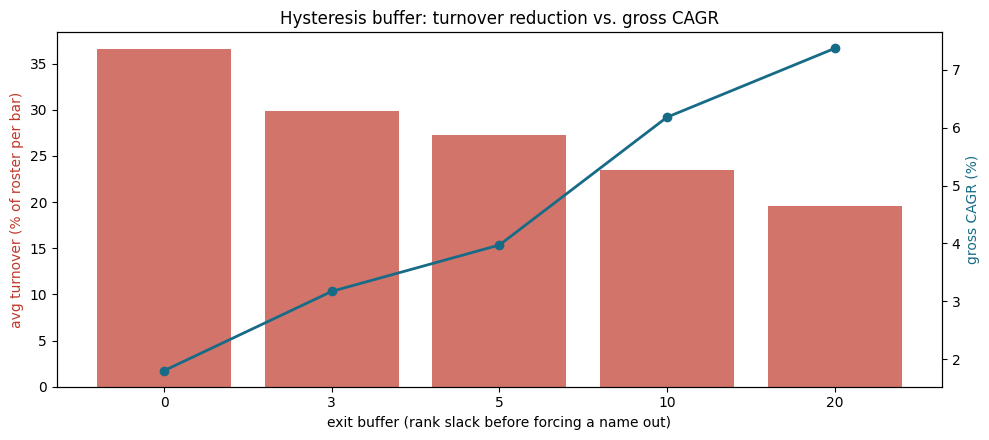

In [10]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
buffers = list(experiment3_results.keys())
avg_turnovers = [experiment3_results[b][1].mean() for b in buffers]
gross_cagrs = [compute_stats(*experiment3_results[b], periods_per_year_hourly, 0)['CAGR'] for b in buffers]

ax1.bar([str(b) for b in buffers], [t * 100 for t in avg_turnovers], color='#c0392b', alpha=0.7, label='avg turnover (%/bar)')
ax1.set_ylabel('avg turnover (% of roster per bar)', color='#c0392b')
ax1.set_xlabel('exit buffer (rank slack before forcing a name out)')
ax2 = ax1.twinx()
ax2.plot([str(b) for b in buffers], [c * 100 for c in gross_cagrs], color='#176b87', marker='o', linewidth=2, label='gross CAGR (%)')
ax2.set_ylabel('gross CAGR (%)', color='#176b87')
ax1.set_title('Hysteresis buffer: turnover reduction vs. gross CAGR')
plt.tight_layout()
plt.show()

## Combined comparison

All Experiment 1 cadences and Experiment 3 hysteresis variants, ranked by `net_pnl_per_turnover`
at `REFERENCE_COST_BPS` — the metric from the original research question that rewards a good
return-to-turnover ratio rather than just the highest gross number.

In [11]:
combined_rows = []
for rb, (pr, to) in experiment1_results.items():
    periods_per_year = (BARS_PER_SESSION * TRADING_DAYS_PER_YEAR) / rb
    stats = compute_stats(pr, to, periods_per_year, cost_bps=REFERENCE_COST_BPS)
    combined_rows.append({'variant': f'block rebalance, every {rb} bar(s)', **stats})
for buf, (pr, to) in experiment3_results.items():
    stats = compute_stats(pr, to, periods_per_year_hourly, cost_bps=REFERENCE_COST_BPS)
    combined_rows.append({'variant': f'hysteresis, exit_buffer={buf}', **stats})

combined = pd.DataFrame(combined_rows).set_index('variant')
combined = combined.sort_values('net_pnl_per_turnover', ascending=False)
display(combined[['avg_turnover', 'CAGR', 'sharpe', 'max_dd', 'net_pnl_per_turnover']].round(4))

,avg_turnover,CAGR,sharpe,max_dd,net_pnl_per_turnover
variant,,,,,
"block rebalance, every 6 bar(s)",0.8645,0.0371,0.2659,-0.5128,0.0002
"block rebalance, every 4 bar(s)",0.7098,-0.0267,0.0223,-0.7276,-0.0001
"block rebalance, every 3 bar(s)",0.6162,-0.0343,-0.0061,-0.7500,-0.0001
"block rebalance, every 2 bar(s)",0.5058,-0.0628,-0.1165,-0.8657,-0.0001
"block rebalance, every 1 bar(s)",0.3656,-0.2699,-1.0385,-0.9968,-0.0001
"hysteresis, exit_buffer=0",0.3656,-0.2706,-1.0422,-0.9968,-0.0001
"hysteresis, exit_buffer=3",0.2988,-0.2144,-0.7647,-0.9879,-0.0001
"hysteresis, exit_buffer=5",0.2728,-0.1894,-0.6498,-0.9793,-0.0001
"hysteresis, exit_buffer=10",0.2344,-0.1426,-0.4444,-0.9466,-0.0001


## Key findings

**1. Gross-of-cost, the live script's current 2-hour cadence is actually one of the better
options tested — not an obviously wrong guess.** Across `rebalance_bars` in {1, 2, 3, 4, 6}
(~1h–6h), gross CAGR was 1.9% / **18.0%** / 16.5% / 14.4% / 18.3% and gross Sharpe was 0.20 /
**0.75** / 0.71 / 0.64 / 0.77. The live setting (2-bar ≈ 2h) and the slowest cadence tested
(6-bar, ~once/day) were essentially tied for best, both well ahead of 1-hour. Re-ranking every
single hourly bar was clearly the worst choice gross of costs, before even considering its much
higher turnover.

**2. Transaction costs change the ranking completely, and even a small assumed cost breaks most
cadences.** At just 5bps round-trip cost, the 2-hour cadence's CAGR falls to **-6.3%** and every
tested cadence except the 6-bar one goes negative; at 10bps every single cadence is deeply
negative (-9% to -73%). The **only** configuration in the entire combined comparison (block
rebalance *and* hysteresis variants) that stays net-positive at a 5bps assumed cost is the
slowest one tested — block rebalance every 6 bars (net CAGR +3.7%, Sharpe 0.27,
`net_pnl_per_turnover` +0.0002; every other row is negative on both). This is the opposite of
what faster rebalancing would predict, and it's driven entirely by turnover: 6-bar cadence
turns over 86.5% of the roster per cycle but only runs ~5,400 cycles over the backtest, versus
1-bar's 36.6%-per-cycle turnover compounding across 32,000+ cycles.

**3. The signal-decay (IC) analysis is the most important and most uncomfortable result here.**
Average Spearman IC between the trailing-6-bar score and forward returns was **weakly negative
at every single horizon tested** (-0.017 to -0.021, IR around -0.09 to -0.11, for horizons from
1 to 24 hourly bars). In a genuinely predictive momentum signal, IC should be positive and
ideally decay toward zero at longer horizons — it should not be negative everywhere. This
directly questions Experiment 1's apparent gross profitability: a top-10 concentrated
backtest's return can diverge from the whole-universe average rank correlation (tail effects,
a few big winners, or performance concentrated in a specific sub-period can all produce this),
but a uniformly negative IC across every horizon is a real warning sign, not a rounding error.
Taken at face value, this suggests the live script's trailing-return signal may have little to
no genuine cross-sectional predictive power at any intraday horizon measured here, and
Experiment 1's backtest returns may not be a reliable estimate of what the live strategy should
expect going forward.

**4. The hysteresis band does what it's supposed to, but doesn't fix the cost problem.**
Buffer 0 → 20 cut average per-bar turnover from 36.6% to 19.6% while *raising* gross CAGR from
1.8% to 7.4% and gross Sharpe from 0.20 to 0.40 — "measure often, trade selectively" is a real,
monotonic improvement over naively re-rebalancing to a fresh top 10 every bar. But even the
largest buffer tested goes net-negative by 2bps of assumed cost (-0.1% CAGR), so this helps at
the margin without changing the headline conclusion.

**Bottom line for the live script:** nothing here says "trade faster." If anything, the data
argues for *slower*, not faster, rebalancing than the current 2-hour cadence, once realistic
costs are assumed — and the IC analysis raises a real question about whether this signal has
genuine edge at any intraday horizon, independent of cadence. Before changing the live cadence
in either direction, the IC-decay finding deserves to be understood — e.g. re-running Experiment
2 on a shorter, cleaner recent window, or checking whether the negative IC is dominated by a
specific regime — rather than treating Experiment 1's backtest numbers alone as a green light.

## Caveats and next steps

- **Hourly-granularity ceiling.** Every interval tested here is a whole multiple of 1 hour,
  because that's the finest bar size cached in `data/hourly/`. The pasted research note's
  30-minute, 15-minute, and genuinely time-of-day-adaptive (fast near the open/close, slow
  midday) ideas are **not tested here** — they'd need 15- or 30-minute bars fetched fresh from
  IBKR. Worth doing as a follow-up only if the hourly-level results above are promising enough
  to justify the fetch (132 tickers x ~17 years at finer granularity is a meaningfully bigger
  pull than the hourly cache was).
- **Cost assumptions are an assumed bps sweep, not calibrated to real spreads.** Webull charges
  $0 commission on US equities (confirmed from the live script's own `preview_order` responses),
  but bid/ask spread and slippage are real and almost certainly vary a lot across this halal
  universe's liquidity range — a single large-cap name's spread is not representative of the
  full 132-ticker universe. `COST_BPS_GRID` brackets a plausible range rather than asserting a
  "true" number.
- **IC analysis vs. backtest tension.** If Experiment 2's measured IC is weak (or negative) at
  every horizon while Experiment 1's top-10 backtest still shows a gross edge, read that as a
  warning rather than a contradiction to explain away: it suggests whatever edge the top-decile
  backtest found may be concentrated in a specific period or a small number of names, not a
  broad, robust cross-sectional effect — exactly the kind of thing that tends not to survive
  outside the backtest window.
- **Bar-close fills, no slippage or gap risk**, same simplifying assumption as every other
  notebook in this project, except this one rebalances far more often, which (as the cost grid
  above shows directly) is precisely where that assumption matters most.
- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of
  halal candidates, projected backward — same caveat as every other notebook here.
- **The live system is throttled by settled cash**; this backtest assumes unconstrained full
  rebalancing every cycle, so live performance at any of these cadences should be expected to
  lag what's shown here.
- This notebook does not change the live script. Any cadence/lookback change based on these
  results would need to be made deliberately in
  `relative_strength_rotation/live/relative_strength_rotation_webull_intraday.py` (and its cron schedule) afterward.